# EDA 01. Data Quality and the Target

CRISP-DM phase: Data understanding

This notebook checks that the model table is complete, sets the training and test rows, and looks at the target `flood_next_month` (1 if the county has a flood in the following month).

Decisions agreed for the project:
- Training rows are July 2002 to December 2019, test rows are 2020 to 2024, and 2025 is not scored.
- `flood_this_month` is the baseline to beat, not a feature.
- Label and source columns and `heavy_rain_next_month` are never features.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

### 1.2 Loading the Dataset

In [2]:
#loading the full model table (pcode is kept as text)
df = pd.read_csv('../../data/private/model_table_full.csv', dtype={'pcode': str})
df.shape

(14664, 70)

In [3]:
#number of counties and rows per county
print(df['pcode'].nunique())
print(df['pcode'].value_counts().unique())

47
[312]


In [4]:
#checking for duplicate county-months
df.duplicated(['pcode', 'year', 'month']).sum()

np.int64(0)

#### Observation

The model table has 14,664 rows and 70 columns. There are 47 counties with 312 rows each (26 years × 12 months, 2000 to 2025) and no duplicate county-months, so every county has exactly one row per month.

## 2. Missing Values

In [5]:
#columns with missing values
missing = df.isna().sum()
missing[missing > 0]

ndvi                       1410
ndvi_pct_normal            1410
flood_next_month             47
flood_next_month_public      47
heavy_rain_next_month        47
dtype: int64

In [6]:
#years with missing ndvi
df[df['ndvi'].isna()]['year'].value_counts()

year
2000    564
2001    564
2002    282
Name: count, dtype: int64

In [7]:
#months with missing flood_next_month
df[df['flood_next_month'].isna()][['year', 'month']].value_counts()

year  month
2025  12       47
Name: count, dtype: int64

#### Observation

Only 5 columns have missing values. `ndvi` and `ndvi_pct_normal` are missing in 1,410 rows, all from January 2000 to June 2002 (564 + 564 + 282), because the NDVI record starts in July 2002. The three next-month columns are missing in 47 rows, all in December 2025, because there is no January 2026 to look at. Both gaps have a clear reason, and the July 2002 start removes the NDVI gap.

## 3. Train and Test Rows

| rows | months | why |
|---|---|---|
| removed | January 2000 to June 2002 | NDVI does not exist yet |
| train | July 2002 to December 2019 | used to learn and to choose features |
| test | January 2020 to December 2024 | kept for the final score |
| not scored | 2025 | labels are incomplete |

In [8]:
#year and month as one number, for example July 2002 becomes 200207
df['year_month'] = df['year'] * 100 + df['month']

In [9]:
#making the train and test sets
train = df[(df['year_month'] >= 200207) & (df['year_month'] <= 201912)]
test = df[(df['year_month'] >= 202001) & (df['year_month'] <= 202412)]

print(train.shape)
print(test.shape)

(9870, 71)
(2820, 71)


In [10]:
#number of floods next month and flood rate in train and test
print(train['flood_next_month'].sum(), train['flood_next_month'].mean())
print(test['flood_next_month'].sum(), test['flood_next_month'].mean())

882.0 0.08936170212765958
144.0 0.05106382978723404


#### Observation

The training set has 9,870 rows (47 counties × 210 months) with 882 floods next month, a rate of 8.9%. The test set has 2,820 rows (47 counties × 60 months) with 144 floods, a rate of 5.1%. Floods are rare in both sets, so a model that always says "no flood" would be right about 91% of the time in train and 95% in test. This is why accuracy is not a useful score here.

### 3.1 Flood Rate by Year

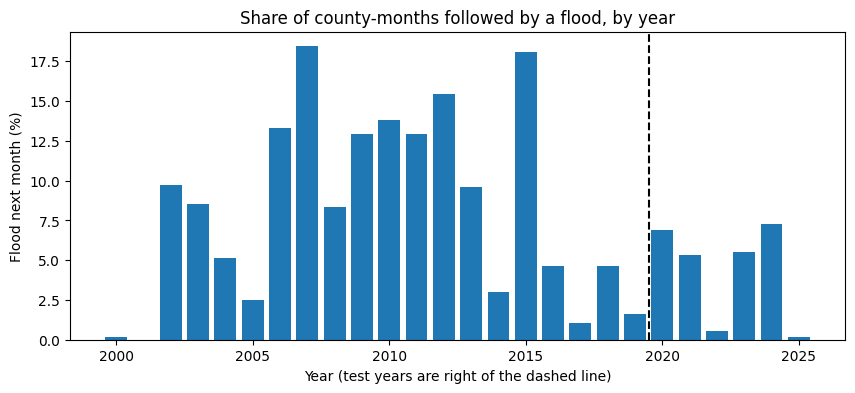

In [11]:
#share of county-months followed by a flood, by year
rate_year = df.groupby('year')['flood_next_month'].mean() * 100

plt.figure(figsize=(10, 4))
plt.bar(rate_year.index, rate_year.values)
plt.axvline(2019.5, color='black', linestyle='--')
plt.xlabel('Year (test years are right of the dashed line)')
plt.ylabel('Flood next month (%)')
plt.title('Share of county-months followed by a flood, by year')
plt.show()

In [12]:
#flood rate by year as numbers
rate_year.round(1)

year
2000     0.2
2001     0.0
2002     9.8
2003     8.5
2004     5.1
2005     2.5
2006    13.3
2007    18.4
2008     8.3
2009    12.9
2010    13.8
2011    12.9
2012    15.4
2013     9.6
2014     3.0
2015    18.1
2016     4.6
2017     1.1
2018     4.6
2019     1.6
2020     6.9
2021     5.3
2022     0.5
2023     5.5
2024     7.3
2025     0.2
Name: flood_next_month, dtype: float64

#### Observation

The flood rate changes a lot from year to year. In the training years it goes from 2.5% (2005) to 18.4% (2007) and 18.1% (2015), and it is much lower from 2016 (1.1% in 2017, 1.6% in 2019). The test years are between 0.5% (2022) and 7.3% (2024). The test period has fewer floods than most training years, so the model should not expect the training rate in the test years.

### 3.2 Why 2025 Is Not Scored

In [13]:
#flood months reported by each source, 2016 to 2025
sources = ['flood_desinventar', 'flood_emdat', 'flood_gfd_dfo', 'flood_this_month']
df[df['year'] >= 2016].groupby('year')[sources].sum().T

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
flood_desinventar,6,0,0,0,4,2,3,4,3,1
flood_emdat,22,0,26,9,36,28,0,28,39,0
flood_gfd_dfo,25,6,2,0,0,0,0,0,0,0
flood_this_month,50,6,26,9,39,30,3,31,41,1


#### Observation

From 2018 almost all flood months come from EM-DAT (for example 36 of 39 in 2020 and 39 of 41 in 2024), and the satellite source GFD/DFO reports nothing after 2018. In 2025 only 1 flood month is reported, because the EM-DAT file has no 2025 events yet. The missing floods in 2025 are missing labels, not dry months, which is why 2025 is not scored.

## 4. When and Where Floods Happen

### 4.1 Flood Rate by Month

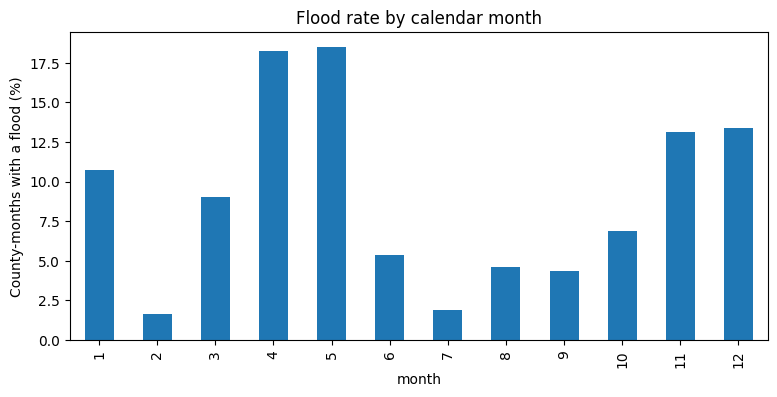

In [14]:
#share of county-months with a flood, by calendar month (training rows)
month_rate = train.groupby('month')['flood_this_month'].mean() * 100
month_rate.plot(kind='bar', figsize=(9, 4))
plt.ylabel('County-months with a flood (%)')
plt.title('Flood rate by calendar month')
plt.show()

In [15]:
#flood rate by month as numbers
month_rate.round(1)

month
1     10.8
2      1.6
3      9.0
4     18.3
5     18.5
6      5.4
7      1.9
8      4.6
9      4.4
10     6.9
11    13.1
12    13.4
Name: flood_this_month, dtype: float64

#### Observation

Floods follow the two rainy seasons. The flood rate peaks in April and May (18.3% and 18.5%) for the long rains and in November and December (13.1% and 13.4%) for the short rains, and it is lowest in February (1.6%) and July (1.9%). The time of year will be an important feature.

### 4.2 Flood Rate by County

In [16]:
#flood months and flood rate (%) in each county (training rows)
by_county = train.groupby('county')['flood_this_month'].agg(['sum', 'mean'])
by_county['mean'] = (by_county['mean'] * 100).round(1)
by_county = by_county.sort_values('mean', ascending=False)
by_county.head(5)

,sum,mean
county,,
Kisumu,47,22.4
Turkana,42,20.0
Tana River,36,17.1
Kilifi,34,16.2
Homa Bay,33,15.7


In [17]:
#counties with the fewest floods
by_county.tail(5)

,sum,mean
county,,
Nyeri,4,1.9
Vihiga,2,1.0
Nyamira,2,1.0
Bomet,1,0.5
Tharaka-Nithi,1,0.5


#### Observation

Some counties flood much more than others. Kisumu has a flood in 22.4% of training months (47 months), Turkana in 20.0% and Tana River in 17.1%, while Bomet and Tharaka-Nithi have only 1 flood month each (0.5%). Where a county is matters as much as when.

## 5. The Baseline: Does a Flood Now Predict a Flood Next Month?

In [18]:
#chance of a flood next month, without (0) and with (1) a flood this month
train.groupby('flood_this_month')['flood_next_month'].mean().round(3)

flood_this_month
0    0.053
1    0.463
Name: flood_next_month, dtype: float64

In [19]:
#auc of the baseline in train and test
print(roc_auc_score(train['flood_next_month'], train['flood_this_month']))
print(roc_auc_score(test['flood_next_month'], test['flood_this_month']))

0.7049240256850404
0.721910812157449


#### Observation

A flood next month follows 46.3% of the months with a flood but only 5.3% of the months without one, so a flood now makes a flood next month about 9 times more likely. Used as a predictor on its own, `flood_this_month` has an AUC of 0.705 in train and 0.722 in test. This is the baseline: any model must beat it, and `flood_this_month` is not used as a feature, otherwise the model would only copy the present.

## 6. Summary

The model table is complete apart from two explained gaps (NDVI before July 2002 and the next-month columns in December 2025). The training set has 9,870 rows with an 8.9% flood rate and the test set has 2,820 rows with a 5.1% flood rate, so accuracy is not a useful score. 2025 is not scored because its labels are incomplete. Floods follow the two rainy seasons and a few counties have most of them. A flood this month makes a flood next month about 9 times more likely, which gives a baseline AUC of 0.705 in train and 0.722 in test for the models to beat. The next notebook, `02_rain_vegetation_climate_vs_target`, checks which rain, vegetation and ocean features go with a flood next month.